In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
print("Pustaka Decision Tree dan Random Forest berhasil dimuat.")

Pustaka Decision Tree dan Random Forest berhasil dimuat.


In [2]:
# Memuat data ulasan dan aspek
path_reviews = '../outputs/reviews_preprocessed.csv'
if not os.path.exists(path_reviews):
    path_reviews = '../dataset/reviews.csv'
path_aspects = '../dataset/aspect_sentiments.csv'

df_reviews = pd.read_csv(path_reviews)
df_aspects = pd.read_csv(path_aspects)

if 'cleaned_text' not in df_reviews.columns:
    df_reviews['cleaned_text'] = df_reviews['text'].str.lower().str.replace(r'[^a-zA-Z\s]', ' ', regex=True).str.strip()

# Gabungkan data ulasan dan aspek
df_aspect_data = pd.merge(df_aspects[['review_id', 'aspect']], df_reviews[['id', 'cleaned_text']], left_on='review_id', right_on='id')
df_aspect_data = df_aspect_data[df_aspect_data['cleaned_text'].str.len() > 3].drop_duplicates().reset_index(drop=True)

X_text = df_aspect_data['cleaned_text']
y_aspect = df_aspect_data['aspect']

# Stratified Splitting 80% Train, 20% Test
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_text, y_aspect, test_size=0.20, random_state=42, stratify=y_aspect
)

print(f"Data latih aspek : {len(X_train_raw):,} sampel")
print(f"Data uji aspek   : {len(X_test_raw):,} sampel")
print("\nDistribusi Target Kategori Aspek (%):")
print((y_aspect.value_counts(normalize=True)*100).round(2).to_dict())

Data latih aspek : 7,405 sampel
Data uji aspek   : 1,852 sampel

Distribusi Target Kategori Aspek (%):
{'food_beverage': 41.91, 'ambience': 33.0, 'facility': 13.98, 'price': 11.11}


In [3]:
# Ekstraksi fitur teks TF-IDF
vec_tfidf = TfidfVectorizer(max_features=800, min_df=3, ngram_range=(1, 2))
X_train_vec = vec_tfidf.fit_transform(X_train_raw)
X_test_vec  = vec_tfidf.transform(X_test_raw)
feature_names = vec_tfidf.get_feature_names_out()

print(f"Dimensi matriks fitur latih: {X_train_vec.shape}")

Dimensi matriks fitur latih: (7405, 800)


In [4]:
# Menguji variasi max_depth Decision Tree untuk menganalisis trade-off bias vs variansi
depth_list = [5, 10, 15, 20, 30, None]
dt_results = []

for d in depth_list:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42, criterion='gini')
    dt.fit(X_train_vec, y_train)
    
    train_acc = accuracy_score(y_train, dt.predict(X_train_vec))
    test_acc  = accuracy_score(y_test, dt.predict(X_test_vec))
    
    d_label = str(d) if d is not None else 'Unconstrained'
    dt_results.append({'Max_Depth': d_label, 'Train_Accuracy': round(train_acc, 4), 'Test_Accuracy': round(test_acc, 4)})

df_dt_tune = pd.DataFrame(dt_results)
print("=== PENGARUH KEDALAMAN POHON TERHADAP OVERFITTING DECISION TREE ===")
print(df_dt_tune.to_string(index=False))

# Model Decision Tree optimal terpilih
best_dt = DecisionTreeClassifier(max_depth=15, random_state=42)
best_dt.fit(X_train_vec, y_train)

=== PENGARUH KEDALAMAN POHON TERHADAP OVERFITTING DECISION TREE ===
    Max_Depth  Train_Accuracy  Test_Accuracy
            5          0.5426         0.5049
           10          0.5919         0.4509
           15          0.6204         0.4077
           20          0.6354         0.3753
           30          0.6492         0.3634
Unconstrained          0.6616         0.3467


In [5]:
# Membangun model Random Forest dengan 100 estimator pohon
rf_model = RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
rf_model.fit(X_train_vec, y_train)

# Prediksi model
y_pred_dt = best_dt.predict(X_test_vec)
y_pred_rf = rf_model.predict(X_test_vec)

acc_dt = accuracy_score(y_test, y_pred_dt)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f"Akurasi Decision Tree (max_depth=15) : {acc_dt*100:.2f}%")
print(f"Akurasi Random Forest (100 Trees)     : {acc_rf*100:.2f}% (Peningkatan: +{(acc_rf - acc_dt)*100:.2f}%)")

print("\nClassification Report: Random Forest Classifier:")
print(classification_report(y_test, y_pred_rf, digits=4))

Akurasi Decision Tree (max_depth=15) : 40.77%
Akurasi Random Forest (100 Trees)     : 39.69% (Peningkatan: +-1.08%)

Classification Report: Random Forest Classifier:
               precision    recall  f1-score   support

     ambience     0.3559    0.3437    0.3497       611
     facility     0.2115    0.1274    0.1590       259
food_beverage     0.4685    0.6134    0.5312       776
        price     0.1778    0.0777    0.1081       206

     accuracy                         0.3969      1852
    macro avg     0.3034    0.2905    0.2870      1852
 weighted avg     0.3631    0.3969    0.3722      1852



Top 10 Kata Kunci Penentu Aspek:
Kata_Kunci  Tingkat_Kepentingan
    nyaman             0.061479
    tempat             0.048795
      enak             0.046675
     harga             0.038622
     murah             0.032888
       wfc             0.025922
     nugas             0.023708
    parkir             0.016646
      kopi             0.016231
    mantap             0.015778


<string>:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

<string>:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



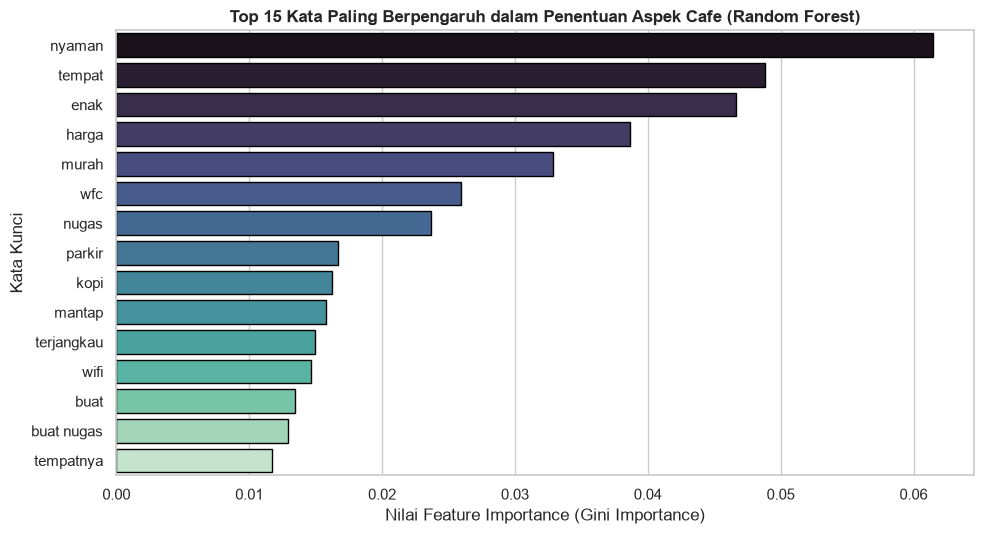

In [6]:
# Ekstraksi Feature Importance dari model Random Forest
importances = rf_model.feature_importances_
top_idx = np.argsort(importances)[::-1][:15]

df_fi = pd.DataFrame({
    'Kata_Kunci': feature_names[top_idx],
    'Tingkat_Kepentingan': importances[top_idx]
})

plt.figure(figsize=(10, 5.5))
sns.barplot(data=df_fi, y='Kata_Kunci', x='Tingkat_Kepentingan', palette='mako', edgecolor='black')
plt.title('Top 15 Kata Paling Berpengaruh dalam Penentuan Aspek Cafe (Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Nilai Feature Importance (Gini Importance)')
plt.ylabel('Kata Kunci')
plt.tight_layout()
plt.show()

print("Top 10 Kata Kunci Penentu Aspek:")
print(df_fi.head(10).to_string(index=False))

<string>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



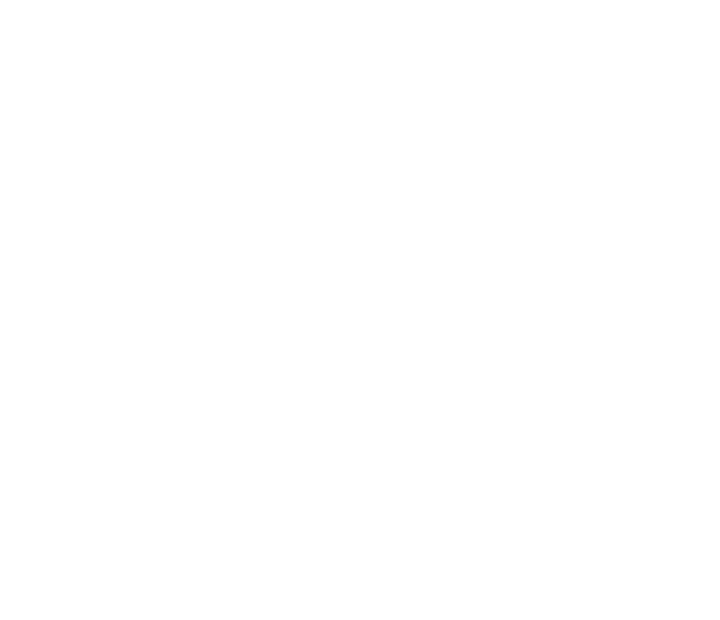

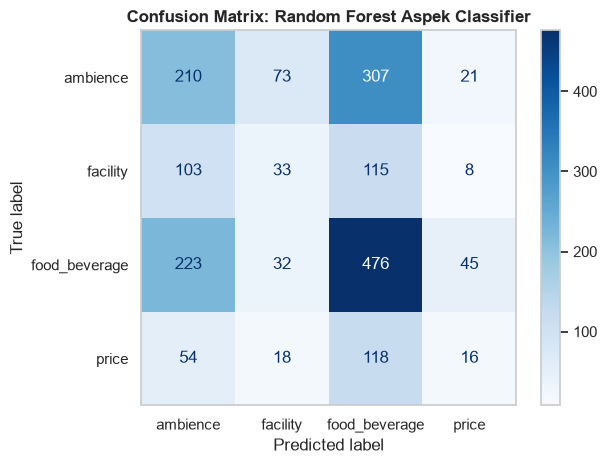

In [7]:
classes = sorted(y_aspect.unique())
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=classes)

plt.figure(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=classes)
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix: Random Forest Aspek Classifier', fontsize=12, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

In [8]:
import joblib

os.makedirs('../outputs', exist_ok=True)
path_saved_rf = '../outputs/random_forest_aspect_js10.joblib'
joblib.dump({'model': rf_model, 'vectorizer': vec_tfidf}, path_saved_rf)
print(f"Model Random Forest Aspek tersimpan ke: {path_saved_rf}")

Model Random Forest Aspek tersimpan ke: ../outputs/random_forest_aspect_js10.joblib
